<div dir="rtl" align="right">

# Oman Analog Explorer — كيف تأتي البيانات وكيف تُحلَّل

هذا الملف يشرح المسار الكامل للمشروع خطوة بخطوة، ويشغّل الكود الحقيقي الموجود في `analysis/src/analog/`:

```
NASA data  →  clip window  →  metrics (terrain, minerals, surface)  →  normalise 0..1
           →  similarity per criterion  →  weighted score + confidence  →  sites.json  →  website
```

**الأقسام:**
1. الإعداد
2. المواقع: ماذا نقارن بماذا
3. من أين تأتي البيانات (تحميل حي من ناسا)
4. مقاييس التضاريس: الانحدار، الخشونة، التضاريس النسبية
5. الألبيدو (نسبة انعكاس الضوء)
6. مؤشرات المعادن (عمق نطاق الامتصاص)
7. القصور الحراري
8. القيم المقاسة والقيم الناقصة (مع أسبابها)
9. التطبيع (Normalisation)
10. مؤشر التشابه: مثال محسوب يدوياً
11. درجة الثقة
12. مصفوفة النتائج والتحقق بموقع AMADEE-18
13. **تدقيق دقة البيانات**: التغطية، مدى التطبيع، الحساسية، والفحوصات التقنية

> الشرح بالعربية، أما الرسوم والكود فبالإنجليزية حتى تظهر النصوص في الرسوم بشكل صحيح.

</div>

<div dir="rtl" align="right">

## 1. الإعداد

نضيف مجلد `src` إلى مسار Python حتى نستخدم نفس الدوال التي يستخدمها المشروع، لا نسخة منها.
المتغير `RUN_LIVE` يتحكم في تحميل البيانات الحية من ناسا (يحتاج إنترنت، حوالي 15 ثانية). إذا جعلته `False` يكمل الملف بالقيم المحفوظة.

</div>

In [1]:
import sys, json, math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALYSIS = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ANALYSIS / "src"))

from analog.export import build, load_config, load_yaml, load_measured
from analog.normalize import normalize_value, resolution_factor
from analog.similarity import similarity
from analog.metrics import terrain, mineralogy, surface
from analog.download.sites import load_sites

RUN_LIVE = True          # set False to work offline with the saved metrics
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

config = load_config()
sites = load_sites()
print("criteria:", {k: v["weight"] for k, v in config["criteria"].items()})
print("sites:", list(sites))

criteria: {'terrain': 0.4, 'mineralogy': 0.4, 'surface': 0.2}
sites: ['samail_ophiolite', 'umm_as_samim', 'sharqiya_sands', 'dhofar_amadee18', 'jebel_shams', 'jezero_crater', 'nili_fossae', 'terra_sirenum_chlorides', 'nili_patera_dunes', 'moon_south_pole']


<div dir="rtl" align="right">

## 2. المواقع: ماذا نقارن بماذا

المواقع معرّفة في ملفين:
- `config/earth_sites.yaml`: خمسة مواقع في عُمان.
- `config/target_sites.yaml`: أربعة مواقع على المريخ وموقع واحد على القمر.

لكل موقع: الإحداثيات، ونصف عرض نافذة القص `bbox_km` (نقص مربعاً صغيراً حول الموقع ولا نحمّل المشهد كاملاً)، والدقة المكانية لكل مصدر، والقيم التقديرية `provisional_metrics`.

</div>

In [2]:
rows = []
for s in sites.values():
    rows.append({
        "id": s["id"], "body": s["body"], "lat": s["lat"], "lon": s["lon"],
        "window_km": 2 * s["bbox_km"], "role": s.get("role", "target"),
        "compared_with": ", ".join(s.get("intended_targets", [])) or "-",
    })
sites_df = pd.DataFrame(rows).set_index("id")
sites_df

,body,lat,lon,window_km,role,compared_with
id,,,,,,
samail_ophiolite,earth,22.90,58.450,20,analog,"jezero_crater, nili_fossae"
umm_as_samim,earth,21.30,56.000,30,analog,terra_sirenum_chlorides
sharqiya_sands,earth,21.90,58.800,30,analog,nili_patera_dunes
dhofar_amadee18,earth,18.80,55.400,20,reference,-
jebel_shams,earth,23.24,57.260,20,analog,moon_south_pole
jezero_crater,mars,18.44,77.450,20,target,-
nili_fossae,mars,21.50,74.500,30,target,-
terra_sirenum_chlorides,mars,-27.28,-179.544,10,target,-
nili_patera_dunes,mars,8.80,67.300,20,target,-


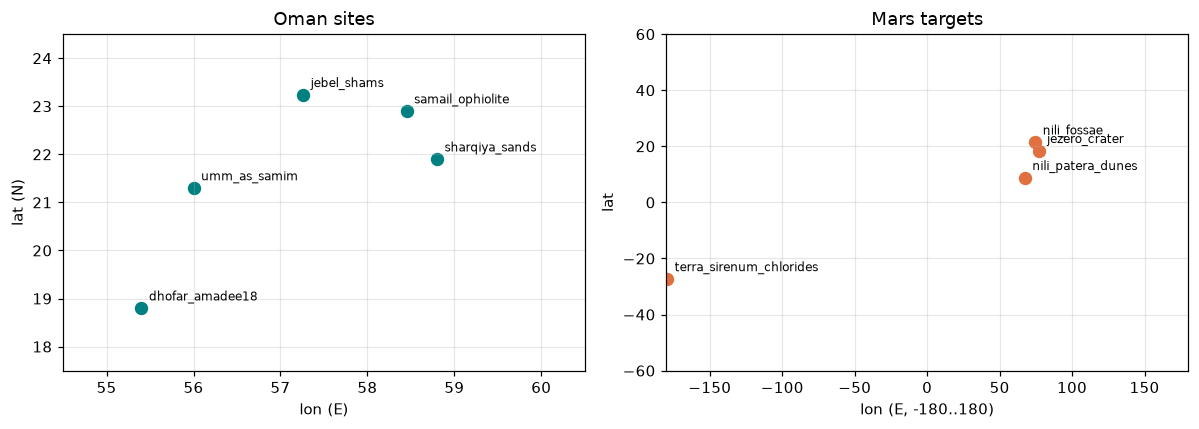

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
earth = sites_df[sites_df.body == "earth"]
axes[0].scatter(earth.lon, earth.lat, c="teal", s=60)
for sid, r in earth.iterrows():
    axes[0].annotate(sid, (r.lon, r.lat), textcoords="offset points", xytext=(5, 5), fontsize=8)
axes[0].set(title="Oman sites", xlabel="lon (E)", ylabel="lat (N)", xlim=(54.5, 60.5), ylim=(17.5, 24.5))
mars = sites_df[sites_df.body == "mars"]
axes[1].scatter(mars.lon, mars.lat, c="#e0703f", s=60)
for sid, r in mars.iterrows():
    axes[1].annotate(sid, (r.lon, r.lat), textcoords="offset points", xytext=(5, 5), fontsize=8)
axes[1].set(title="Mars targets", xlabel="lon (E, -180..180)", ylabel="lat", xlim=(-180, 180), ylim=(-60, 60))
plt.tight_layout()

<div dir="rtl" align="right">

## 3. من أين تأتي البيانات

| ماذا نقيس | الأرض (عُمان) | المريخ | القمر |
|---|---|---|---|
| التضاريس | NASADEM دقة 30 م | MOLA دقة 463 م | LOLA دقة 20 م |
| الألبيدو | MODIS MCD43A4 دقة 500 م | TES دقة 7.4 كم | لا يُقارن |
| المعادن | EMIT دقة 60 م (يحتاج حساب Earthdata) | CRISM MTRDR دقة 18 م | لا يُقارن |
| القصور الحراري | غير متاح: لا توجد معايرة موثّقة | THEMIS دقة 100 م (و TES احتياطاً) | لا يُقارن |

**كيف يتم التحميل** (`compute.py`):
1. نبني شبكة محلية مركزها الموقع بإسقاط *Azimuthal Equidistant*، فتكون كل خلية مربعاً بالأمتار حتى في القطب الجنوبي للقمر.
2. نقرأ من الملف البعيد الجزء الذي يغطي النافذة فقط (HTTP range requests).
3. نعيد إسقاط البيانات على الشبكة المحلية، ونسجّل لكل قيمة مصدرها: اسم البيانات والإصدار ومعرّفات المنتجات والتواريخ.

الخلية التالية تحمّل بيانات حقيقية لموقعين: رمال الشرقية من NASADEM، وفوهة Jezero من MOLA.

</div>

In [4]:
from analog.compute import earth_dem, mars_dem

common = config["common_terrain_scale_m"]
dems = {}
if RUN_LIVE:
    try:
        dems["sharqiya_sands"], cov_e, info_e = earth_dem(sites["sharqiya_sands"])
        dems["jezero_crater"], cov_m, info_m = mars_dem(sites["jezero_crater"])
        print("Earth:", info_e["dataset"], info_e["products"], info_e["acquired"])
        print("Mars :", info_m["dataset"], info_m["products"])
    except Exception as exc:
        print("Live download failed, continuing offline:", exc)
for k, v in dems.items():
    print(f"{k}: {common} m grid {v.shape}, elevation {np.nanmin(v):.0f} .. {np.nanmax(v):.0f} m, valid {np.isfinite(v).mean():.0%}")

Earth: NASADEM_HGT (NASA SRTM reprocessing), Microsoft Planetary Computer COG mirror ['NASADEM_HGT_n22e058', 'NASADEM_HGT_n21e058'] ['2000-02-20']
Mars : MGS MOLA DEM global mosaic 463 m (USGS Astrogeology, MOLA Team / GSFC) ['Mars_MGS_MOLA_DEM_mosaic_global_463m']
sharqiya_sands: 463 m grid (65, 65), elevation 184 .. 316 m, valid 100%
jezero_crater: 463 m grid (43, 43), elevation -2687 .. -1734 m, valid 100%


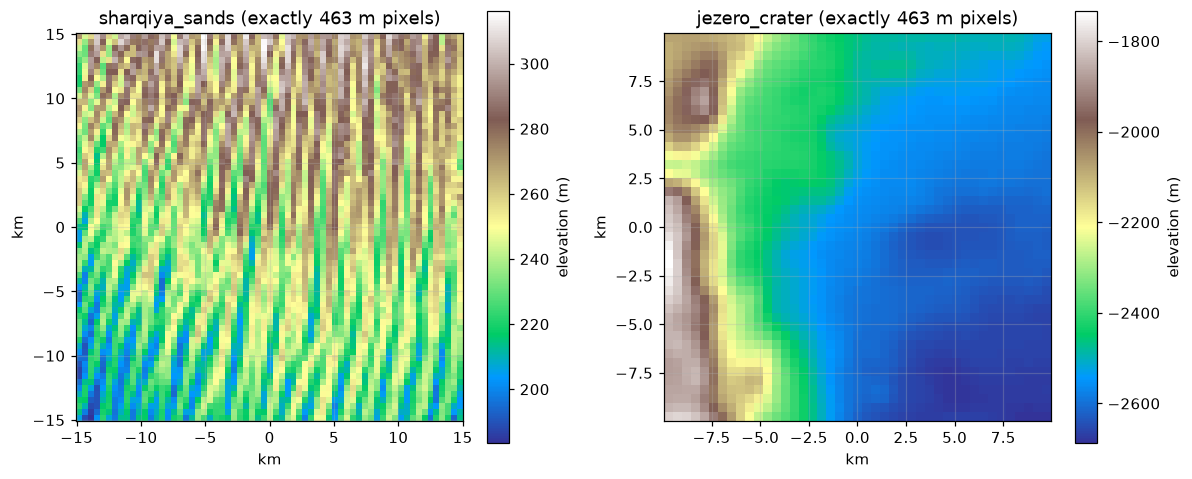

In [5]:
if dems:
    fig, axes = plt.subplots(1, len(dems), figsize=(11, 4.5))
    for ax, (sid, dem) in zip(np.atleast_1d(axes), dems.items()):
        half = dem.shape[0] * common / 2000
        im = ax.imshow(dem, cmap="terrain", extent=[-half, half, -half, half])
        ax.set(title=f"{sid} (exactly {common} m pixels)", xlabel="km", ylabel="km")
        plt.colorbar(im, ax=ax, label="elevation (m)")
    plt.tight_layout()

<div dir="rtl" align="right">

## 4. مقاييس التضاريس

### 4.1 لماذا نوحّد الدقة المكانية أولاً؟
الصورة بدقة 30 م تُظهر تفاصيل صغيرة لا تظهر في صورة بدقة 463 م، فتبدو دائماً **أكثر وعورة**. لو قارنا الأرض (30 م) بالمريخ (463 م) مباشرة لكانت المقارنة مضللة.
لذلك نحسب **متوسطاً موزوناً بالمساحة** لكل نموذج ارتفاع على شبكة بخلايا **463 م تماماً** (`compute.py::average_to`).
الطريقة القديمة (متوسط كتل من 15×15 خلية) كانت تعطي 450 م بدل 463 م.

الخلية التالية توضح الخطوة على تضاريس اصطناعية فوق شبكة رمال الشرقية.

</div>

In [6]:
from analog.compute import average_to, local_grid

# Synthetic 30 m dune field on Sharqiya's real site grid, to show the resampling step on its own.
s = sites["sharqiya_sands"]
crs, t30, shp30 = local_grid(s["lat"], s["lon"], s["bbox_km"], "earth", 30.0)
_, t463, shp463 = local_grid(s["lat"], s["lon"], s["bbox_km"], "earth", common)
y, x = np.mgrid[0:shp30[0], 0:shp30[1]] * 30.0
dem30 = 200 + 25 * np.sin(x / 900) * np.cos(y / 2500) + 8 * np.sin(x / 120)
coarse = average_to(dem30, crs, t30, t463, shp463)

old = int(round(common / 30))
print(f"old method: block factor round({common}/30) = {old} -> {old * 30} m pixels, but slope used {common} m spacing")
print(f"new method: area-weighted average to exactly {t463.a:.0f} m, grid {shp30} -> {coarse.shape}")
print(f"mean slope at 30 m : {np.nanmean(terrain.slope_deg(dem30, 30.0)):.2f} deg")
print(f"mean slope at {common} m: {np.nanmean(terrain.slope_deg(coarse, common)):.2f} deg   <- compared with Mars")

old method: block factor round(463/30) = 15 -> 450 m pixels, but slope used 463 m spacing
new method: area-weighted average to exactly 463 m, grid (1000, 1000) -> (65, 65)
mean slope at 30 m : 2.48 deg
mean slope at 463 m: 0.74 deg   <- compared with Mars


<div dir="rtl" align="right">

### 4.2 الانحدار (Slope)
لكل خلية نحسب التغير في الارتفاع أفقياً وعمودياً (`np.gradient`)، ثم:

$$\text{slope} = \arctan\sqrt{(\partial z/\partial x)^2 + (\partial z/\partial y)^2}$$

قيمة الموقع = **متوسط** الانحدار على كل الخلايا.

### 4.3 الخشونة (RMS roughness)
نقسم الخريطة إلى نوافذ ~1.4 كم. في كل نافذة نطرح **أفضل مستوى مائل** (حتى لا يُحسب الميل العام كخشونة)، ثم نحسب الجذر التربيعي لمتوسط مربعات ما تبقى. قيمة الموقع = **وسيط** النوافذ.

### 4.4 التضاريس النسبية (Relief)
في نوافذ ~5 كم نحسب (أعلى ارتفاع − أدنى ارتفاع)، وقيمة الموقع = **الوسيط**.

</div>

RMS of this window after detrending: 1.91 m
Synthetic terrain metrics: {'slope_deg': 0.735, 'roughness_m': 2.322, 'relief_m': 49.982}


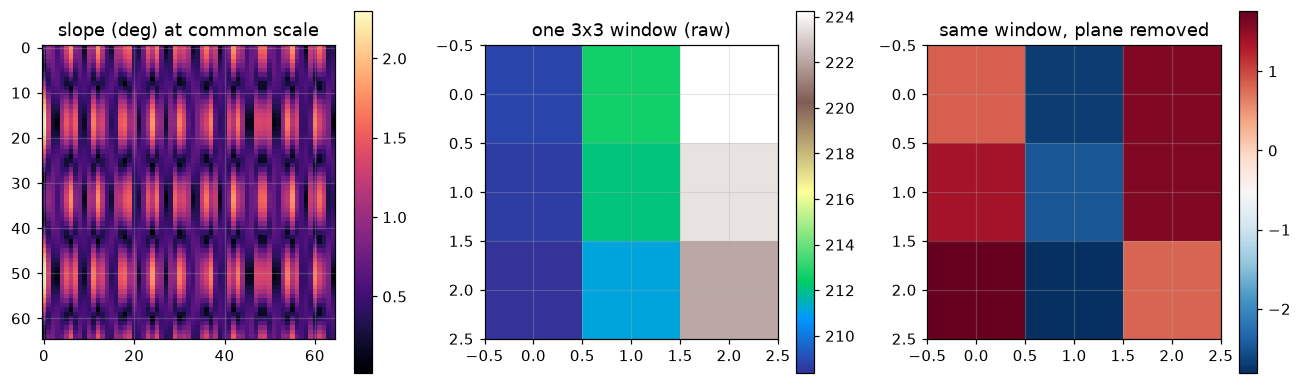

In [7]:
size = max(3, int(round(1400 / common)))
win = coarse[:size, :size]
detr = terrain._detrend_plane(win)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
im0 = axes[0].imshow(terrain.slope_deg(coarse, common), cmap="magma"); axes[0].set_title("slope (deg) at common scale")
plt.colorbar(im0, ax=axes[0])
im1 = axes[1].imshow(win, cmap="terrain"); axes[1].set_title(f"one {size}x{size} window (raw)")
plt.colorbar(im1, ax=axes[1])
im2 = axes[2].imshow(detr, cmap="RdBu_r"); axes[2].set_title("same window, plane removed")
plt.colorbar(im2, ax=axes[2])
plt.tight_layout()

print(f"RMS of this window after detrending: {np.sqrt(np.nanmean(detr**2)):.2f} m")
print("Synthetic terrain metrics:", {k: round(v, 3) for k, v in terrain.terrain_metrics(coarse, common).items()})

In [8]:
if "jezero_crater" in dems:
    print("Jezero (MOLA on the 463 m grid):",
          {k: round(v, 3) for k, v in terrain.terrain_metrics(dems["jezero_crater"], common).items()})
print("Saved measured values in data/processed/metrics (NaN = missing, see section 8):")
pd.DataFrame({sid: {f: m["value"] for f, m in load_measured(sid).get("measured", {}).items()} for sid in sites}).T

Jezero (MOLA on the 463 m grid): {'slope_deg': 2.735, 'roughness_m': 1.937, 'relief_m': 198.596}
Saved measured values in data/processed/metrics (NaN = missing, see section 8):


,slope_deg,roughness_m,relief_m,albedo,thermal_inertia,serpentine_index,carbonate_index
samail_ophiolite,5.109,20.237,368.742,0.136,NaN,NaN,NaN
umm_as_samim,0.371,0.455,14.763,0.357,NaN,NaN,NaN
sharqiya_sands,1.740,7.644,67.575,0.332,NaN,NaN,NaN
dhofar_amadee18,0.193,0.632,12.321,0.480,NaN,NaN,NaN
jebel_shams,15.500,36.576,1379.870,0.165,NaN,NaN,NaN
jezero_crater,2.735,1.937,198.596,0.171,313.531,0.003,1.910e-04
nili_fossae,3.001,1.871,275.825,0.123,301.660,0.003,4.700e-05
terra_sirenum_chlorides,0.378,0.466,39.976,0.169,354.813,0.001,9.000e-06
nili_patera_dunes,1.181,1.423,106.179,0.116,378.500,0.002,1.900e-05
moon_south_pole,20.024,8.271,1885.567,NaN,NaN,NaN,NaN


<div dir="rtl" align="right">

## 5. الألبيدو (Albedo)

الألبيدو = نسبة ضوء الشمس التي يعكسها السطح (0 = أسود تماماً، 1 = أبيض تماماً).

- **الأرض:** MODIS يقيس الانعكاس في نطاقات ضيقة. نحوّلها إلى ألبيدو عريض بمعادلة **Liang (2001)**:

$$\alpha = 0.160\,b_1 + 0.291\,b_2 + 0.243\,b_3 + 0.116\,b_4 + 0.112\,b_5 + 0.081\,b_7 - 0.0015$$

  نحسب ذلك لـ 12 صورة شهرية في 2023، وقيمة الموقع = **وسيط الأشهر** (يقلل أثر الغيوم والغبار).
- **المريخ:** خريطة TES جاهزة للألبيدو، نأخذ وسيط النافذة.

</div>

In [9]:
from analog.compute import liang_albedo, LIANG_MODIS

# Example: typical reflectances for bright desert sand vs dark basalt
examples = {
    "bright sand": {1: 0.35, 2: 0.45, 3: 0.22, 4: 0.30, 5: 0.52, 7: 0.50},
    "dark basalt": {1: 0.10, 2: 0.13, 3: 0.08, 4: 0.09, 5: 0.15, 7: 0.14},
}
for name, bands in examples.items():
    a = liang_albedo({b: np.array(v) for b, v in bands.items()})
    print(f"{name:12s} -> broadband albedo {float(a):.3f}")
print("weights sum to", round(sum(LIANG_MODIS.values()), 3))

bright sand  -> broadband albedo 0.372
dark basalt  -> broadband albedo 0.110
weights sum to 1.003


<div dir="rtl" align="right">

## 6. مؤشرات المعادن (عمق نطاق الامتصاص)

كل معدن يمتص الضوء عند أطوال موجية محددة. نقيس **عمق الامتصاص** (Band Depth):

$$BD = 1 - \frac{R_{center}}{R_{continuum}}$$

حيث الـ continuum خط مستقيم بين كتفي النطاق.

- **السربنتين:** نطاق 2.32 ميكرومتر.
- **الكربونات:** نطاقان معاً، 2.33 و 2.50 ميكرومتر (نأخذ الأصغر). السربنتين لا يملك نطاق 2.5، وهذا ما يفصل بينهما.
- **قيمة الموقع = متوسط عمق النطاق** على كل البكسلات الصالحة في النافذة، بلا عتبة رصد ولا ثابت تشبّع، لأنه لا يوجد مصدر موثّق لهما.
- **الكلوريد لا يُحسب:** ليس له امتصاص مميز بين 0.4 و 2.5 ميكرومتر، ولا توجد عتبة موثّقة (`calibration_missing`).

نفس الدالة تعمل على EMIT (الأرض) و CRISM (المريخ).

</div>

,serpentine_index,carbonate_index
spectrum,,
serpentine-like,0.120,0.0
carbonate-like,0.078,0.1
flat (no mineral band),0.000,0.0


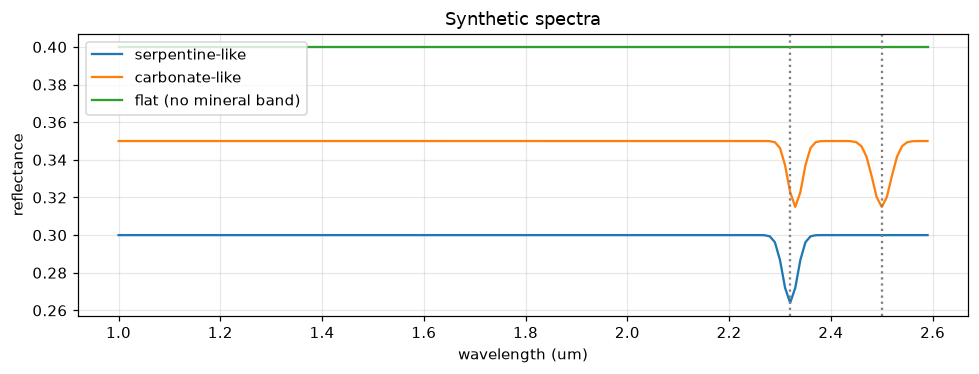

In [10]:
wl = np.round(np.arange(1.0, 2.60, 0.01), 3)

def spectrum(base, dips):
    r = np.full_like(wl, base)
    for center, depth, width in dips:
        r = r * (1 - depth * np.exp(-((wl - center) / width) ** 2))
    return r

spectra = {
    "serpentine-like": spectrum(0.30, [(2.32, 0.12, 0.02)]),
    "carbonate-like": spectrum(0.35, [(2.33, 0.10, 0.02), (2.50, 0.10, 0.025)]),
    "flat (no mineral band)": np.full_like(wl, 0.4),
}

fig, ax = plt.subplots(figsize=(9, 3.5))
rows = []
for name, r in spectra.items():
    ax.plot(wl, r, label=name)
    cube = np.repeat(r[:, None, None], 4, axis=1).repeat(4, axis=2)  # 4x4 pixels, same spectrum
    rows.append({"spectrum": name, **{k: round(v[0], 4) for k, v in mineralogy.mineral_metrics(cube, wl).items()}})
for x in (2.32, 2.50):
    ax.axvline(x, color="grey", ls=":")
ax.set(xlabel="wavelength (um)", ylabel="reflectance", title="Synthetic spectra"); ax.legend()
plt.tight_layout()
pd.DataFrame(rows).set_index("spectrum")

<div dir="rtl" align="right">

## 7. القصور الحراري (Thermal Inertia)

القصور الحراري يدل على نوع السطح: الرمل الناعم يسخن ويبرد بسرعة (قصور منخفض)، والصخر الصلب يحتفظ بالحرارة (قصور مرتفع).

- **المريخ:** نأخذه مباشرة من فسيفساء THEMIS الكمية (دقة 100 م، Fergason وآخرون 2006)، ومن خريطة TES 2007 فقط إذا لم توجد بكسلات THEMIS.
- **الأرض:** من حرارة النهار والليل في MODIS يمكن حساب **القصور الظاهري** فقط:
  $$ATI = \frac{1 - albedo}{T_{day} - T_{night}}$$
  وتحويله إلى قصور حراري بوحدة TIU يحتاج معايرة ليس لها مصدر موثّق لدينا. لذلك القيمة **غير متاحة** (`calibration_missing`) ولا نقدّرها.

</div>

In [11]:
# ATI only illustrates the idea; it is never converted to TIU and never enters the score.
for name, alb, tday, tnight in [("dry sand", 0.35, 330, 285), ("bedrock", 0.15, 320, 300)]:
    ati = surface.apparent_thermal_inertia(np.array([alb]), np.array([tday]), np.array([tnight]))[0]
    print(f"{name:9s} ATI = {ati:.4f}  (not comparable with Mars thermal inertia without a cited calibration)")

dry sand  ATI = 0.0144  (not comparable with Mars thermal inertia without a cited calibration)
bedrock   ATI = 0.0425  (not comparable with Mars thermal inertia without a cited calibration)


<div dir="rtl" align="right">

## 8. القيم المقاسة والقيم الناقصة

لا توجد أي قيمة مكتوبة يدوياً. كل قيمة إما **مقاسة** من مجموعة بيانات مسمّاة (مع معرّفات المنتجات والتواريخ)، أو **ناقصة** مع رمز السبب:
`no_coverage`، `needs_login`، `not_implemented`، `calibration_missing`، `not_applicable`، `download_failed`.

</div>

In [12]:
dataset = build()
all_sites = dataset["earth_sites"] + dataset["targets"]
features = [f for c in config["criteria"].values() for f in c["features"]]

def cell(s, f):
    if s["raw"][f] is not None:
        return "M"
    return next(m["reason_code"] for m in s["missing"] if m["feature"] == f)

status = pd.DataFrame({s["id"]: {f: cell(s, f) for f in features} for s in all_sites}).T
c = dataset["coverage"]
print(f"measured {c['measured']}, unavailable {c['unavailable']}, not applicable {c['not_applicable']} "
      f"-> {c['share']:.0%} of applicable values measured")
status

measured 51, unavailable 24, not applicable 5 -> 68% of applicable values measured


,slope_deg,roughness_m,relief_m,serpentine_index,carbonate_index,chloride_index,albedo,thermal_inertia
samail_ophiolite,M,M,M,needs_login,needs_login,calibration_missing,M,calibration_missing
umm_as_samim,M,M,M,needs_login,needs_login,calibration_missing,M,calibration_missing
sharqiya_sands,M,M,M,needs_login,needs_login,calibration_missing,M,calibration_missing
dhofar_amadee18,M,M,M,needs_login,needs_login,calibration_missing,M,calibration_missing
jebel_shams,M,M,M,needs_login,needs_login,calibration_missing,M,calibration_missing
jezero_crater,M,M,M,M,M,calibration_missing,M,M
nili_fossae,M,M,M,M,M,calibration_missing,M,M
terra_sirenum_chlorides,M,M,M,M,M,calibration_missing,M,M
nili_patera_dunes,M,M,M,M,M,calibration_missing,M,M
moon_south_pole,M,M,M,not_applicable,not_applicable,not_applicable,not_applicable,not_applicable


In [13]:
prov_rows = []
for s in all_sites:
    for f, p in s["provenance"].items():
        prov_rows.append({"site": s["id"], "feature": f, "dataset": p["dataset"][:55],
                          "products": ", ".join(p["products"][:2]) + (" ..." if len(p["products"]) > 2 else ""),
                          "native m": p["native_resolution_m"], "window cov.": p.get("window_coverage")})
pd.DataFrame(prov_rows).set_index(["site", "feature"])

dataset  \
site                    feature                                                               
samail_ophiolite        slope_deg         NASADEM_HGT (NASA SRTM reprocessing), Microsof...   
                        roughness_m       NASADEM_HGT (NASA SRTM reprocessing), Microsof...   
                        relief_m          NASADEM_HGT (NASA SRTM reprocessing), Microsof...   
                        albedo            MODIS MCD43A4 Nadir BRDF-Adjusted Reflectance ...   
umm_as_samim            slope_deg         NASADEM_HGT (NASA SRTM reprocessing), Microsof...   
                        roughness_m       NASADEM_HGT (NASA SRTM reprocessing), Microsof...   
                        relief_m          NASADEM_HGT (NASA SRTM reprocessing), Microsof...   
                        albedo            MODIS MCD43A4 Nadir BRDF-Adjusted Reflectance ...   
sharqiya_sands          slope_deg         NASADEM_HGT (NASA SRTM reprocessing), Microsof...   
                        roughness_m       NASADEM_HGT (NASA SRTM reprocessing), Microsof...   
                        relief_m          NASADEM_HGT (NASA SRTM reprocessing), Microsof...   
                        albedo            MODIS MCD43A4 Nadir BRDF-Adjusted Reflectance ...   
dhofar_amadee18         slope_deg         NASADEM_HGT (NASA SRTM reprocessing), Microsof...   
                        roughness_m       NASADEM_HGT (NASA SRTM reprocessing), Microsof...   
                        relief_m          NASADEM_HGT (NASA SRTM reprocessing), Microsof...   
                        albedo            MODIS MCD43A4 Nadir BRDF-Adjusted Reflectance ...   
jebel_shams             slope_deg         NASADEM_HGT (NASA SRTM reprocessing), Microsof...   
                        roughness_m       NASADEM_HGT (NASA SRTM reprocessing), Microsof...   
                        relief_m          NASADEM_HGT (NASA SRTM reprocessing), Microsof...   
                        albedo            MODIS MCD43A4 Nadir BRDF-Adjusted Reflectance ...   
jezero_crater           slope_deg         MGS MOLA DEM global mosaic 463 m (USGS Astroge...   
                        roughness_m       MGS MOLA DEM global mosaic 463 m (USGS Astroge...   
                        relief_m          MGS MOLA DEM global mosaic 463 m (USGS Astroge...   
                        serpentine_index  MRO CRISM map-projected targeted reduced data ...   
                        carbonate_index   MRO CRISM map-projected targeted reduced data ...   
                        albedo            MGS TES Lambert albedo global mosaic (Christen...   
                        thermal_inertia   Mars Odyssey THEMIS quantitative thermal inert...   
nili_fossae             slope_deg         MGS MOLA DEM global mosaic 463 m (USGS Astroge...   
                        roughness_m       MGS MOLA DEM global mosaic 463 m (USGS Astroge...   
                        relief_m          MGS MOLA DEM global mosaic 463 m (USGS Astroge...   
                        serpentine_index  MRO CRISM map-projected targeted reduced data ...   
                        carbonate_index   MRO CRISM map-projected targeted reduced data ...   
                        albedo            MGS TES Lambert albedo global mosaic (Christen...   
                        thermal_inertia   Mars Odyssey THEMIS quantitative thermal inert...   
terra_sirenum_chlorides slope_deg         MGS MOLA DEM global mosaic 463 m (USGS Astroge...   
                        roughness_m       MGS MOLA DEM global mosaic 463 m (USGS Astroge...   
                        relief_m          MGS MOLA DEM global mosaic 463 m (USGS Astroge...   
                        serpentine_index  MRO CRISM map-projected targeted reduced data ...   
                        carbonate_index   MRO CRISM map-projected targeted reduced data ...   
                        albedo            MGS TES Lambert albedo global mosaic (Christen...   
                        thermal_inertia   Mars Odyssey THEMIS quantitative thermal inert...   

<div dir="rtl" align="right">

**كيف تقرأ الجدولين:** `M` تعني قيمة مقاسة، وغير ذلك رمز سبب النقص. الجدول الثاني يبيّن مصدر كل قيمة مقاسة: مجموعة البيانات ومعرّفات المنتجات والدقة الأصلية، ونسبة النافذة التي تغطيها البيانات (مهمة لـ CRISM لأن مشاهداته لا تغطي إلا جزءاً من النافذة).

</div>

<div dir="rtl" align="right">

## 9. التطبيع (Normalisation)

لا يمكن مقارنة "12 درجة" مع "600 متر" مباشرة. لذلك نحوّل كل قيمة إلى 0–1:

$$norm(x) = \text{clip}\left(\frac{x' - min}{max - min}, 0, 1\right)$$

- **min و max** هما أقل وأعلى قيمة **مقاسة** في كل المواقع معاً (الأرض والمريخ والقمر)، ويحسبها `export.py` تلقائياً. لا نختارها يدوياً.
- **الخشونة والتضاريس النسبية** تمتدان على رتبتين عشريتين، لذا $x' = \log_{10} x$.
- الخاصية المقاسة في أقل من موقعين ليس لها مدى ولا تُقارن.

</div>

In [14]:
scoring = dataset["config"]
ranges, scales = scoring["feature_ranges"], scoring.get("feature_scale", {})
pd.DataFrame({f: {"scale": scales.get(f, "linear"), "min": r[0] if r else None, "max": r[1] if r else None}
              for f, r in ranges.items()}).T

,scale,min,max
slope_deg,linear,0.193,20.024
roughness_m,log10,-0.342,1.563
relief_m,log10,1.091,3.275
serpentine_index,linear,0.001,0.003
carbonate_index,linear,0.0,0.0
chloride_index,linear,NaN,NaN
albedo,linear,0.116,0.48
thermal_inertia,linear,301.66,378.5


In [15]:
norm = pd.DataFrame({s["id"]: {f: normalize_value(s["raw"].get(f), ranges[f], scales.get(f)) for f in features}
                     for s in all_sites}).T
raw = pd.DataFrame({s["id"]: s["raw"] for s in all_sites}).T[features]
print("Raw values (NaN = not available):")
display(raw.astype(float).round(4))
print("Normalised 0..1:")
display(norm.astype(float).round(3))

Raw values (NaN = not available):


,slope_deg,roughness_m,relief_m,serpentine_index,carbonate_index,chloride_index,albedo,thermal_inertia
samail_ophiolite,5.109,20.237,368.742,NaN,NaN,NaN,0.136,NaN
umm_as_samim,0.371,0.455,14.763,NaN,NaN,NaN,0.357,NaN
sharqiya_sands,1.740,7.644,67.575,NaN,NaN,NaN,0.332,NaN
dhofar_amadee18,0.194,0.632,12.321,NaN,NaN,NaN,0.480,NaN
jebel_shams,15.500,36.576,1379.870,NaN,NaN,NaN,0.165,NaN
jezero_crater,2.735,1.937,198.596,0.003,2.000e-04,NaN,0.171,313.531
nili_fossae,3.001,1.871,275.825,0.003,0.000e+00,NaN,0.123,301.660
terra_sirenum_chlorides,0.378,0.466,39.976,0.002,0.000e+00,NaN,0.169,354.813
nili_patera_dunes,1.181,1.423,106.179,0.002,0.000e+00,NaN,0.116,378.500
moon_south_pole,20.024,8.271,1885.567,NaN,NaN,NaN,NaN,NaN


Normalised 0..1:


,slope_deg,roughness_m,relief_m,serpentine_index,carbonate_index,chloride_index,albedo,thermal_inertia
samail_ophiolite,0.248,0.865,0.676,NaN,NaN,NaN,0.055,NaN
umm_as_samim,0.009,0.000,0.036,NaN,NaN,NaN,0.663,NaN
sharqiya_sands,0.078,0.643,0.338,NaN,NaN,NaN,0.592,NaN
dhofar_amadee18,0.000,0.075,0.000,NaN,NaN,NaN,1.000,NaN
jebel_shams,0.772,1.000,0.938,NaN,NaN,NaN,0.134,NaN
jezero_crater,0.128,0.330,0.553,1.000,1.000,NaN,0.152,0.154
nili_fossae,0.142,0.322,0.618,0.884,0.209,NaN,0.021,0.000
terra_sirenum_chlorides,0.009,0.005,0.234,0.000,0.000,NaN,0.145,0.692
nili_patera_dunes,0.050,0.260,0.428,0.211,0.055,NaN,0.000,1.000
moon_south_pole,1.000,0.661,1.000,NaN,NaN,NaN,NaN,NaN


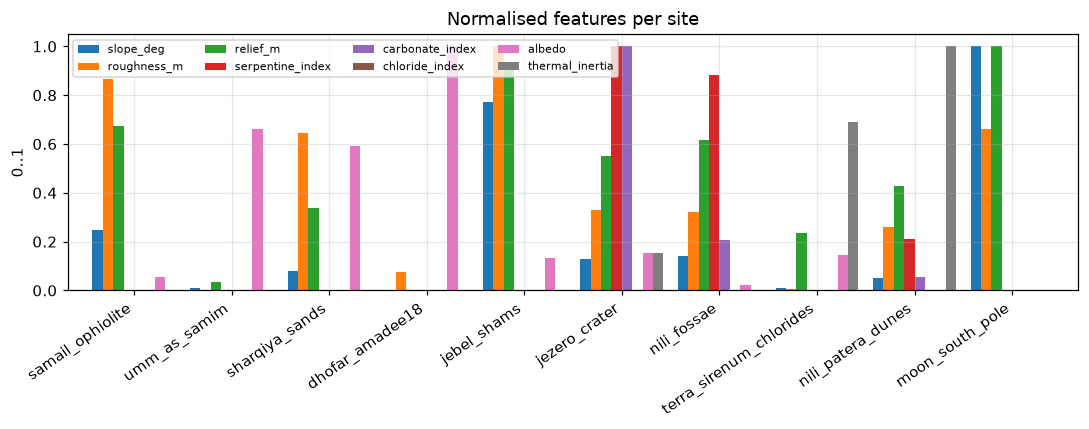

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
norm.astype(float).plot.bar(ax=ax, width=0.85)
ax.set(title="Normalised features per site", ylabel="0..1"); ax.legend(ncol=4, fontsize=7)
plt.xticks(rotation=35, ha="right"); plt.tight_layout()

<div dir="rtl" align="right">

## 10. مؤشر التشابه: مثال محسوب يدوياً

لكل معيار نحسب متوسط $1 - |norm_a - norm_b|$ على الخصائص **المقاسة في الطرفين** فقط، ثم المتوسط الموزون:

$$overall = \frac{\sum_c w_c \cdot score_c}{\sum_c w_c}$$

بالأوزان الافتراضية: تضاريس 0.4، معادن 0.4، سطح 0.2. نحسب **أفيوليت سمائل مقابل Nili Fossae** يدوياً ونتأكد أن النتيجة تطابق دالة المشروع.

</div>

In [17]:
A = next(s for s in all_sites if s["id"] == "samail_ophiolite")
B = next(s for s in all_sites if s["id"] == "nili_fossae")

rows, by_crit, shared = [], {}, {}
for crit, spec in config["criteria"].items():
    vals = []
    for f in spec["features"]:
        na = normalize_value(A["raw"][f], ranges[f], scales.get(f))
        nb = normalize_value(B["raw"][f], ranges[f], scales.get(f))
        sim = None if na is None or nb is None else 1 - abs(na - nb)
        if sim is not None:
            vals.append(sim)
        rows.append({"criterion": crit, "feature": f, "Samail raw": A["raw"][f], "Nili raw": B["raw"][f],
                     "Samail norm": na, "Nili norm": nb, "1-|diff|": sim})
    by_crit[crit] = np.mean(vals) if vals else None
    shared[crit] = len(vals) / len(spec["features"])
display(pd.DataFrame(rows).set_index(["criterion", "feature"]))

w = {c: s["weight"] for c, s in config["criteria"].items()}
used = [c for c in w if by_crit[c] is not None]
manual = sum(w[c] * by_crit[c] for c in used) / sum(w[c] for c in used)
manual_cov = sum(w[c] * shared[c] for c in w) / sum(w.values())
lib = similarity(A["raw"], B["raw"], A["resolution_m"], B["resolution_m"], scoring)
print("per-criterion:", {c: (round(v, 3) if v is not None else None) for c, v in by_crit.items()})
print(f"manual overall = {manual:.4f}   library overall = {lib['overall']:.4f}")
print(f"manual coverage = {manual_cov:.4f}   library coverage = {lib['coverage']:.4f}")
assert abs(manual - lib["overall"]) < 1e-9 and abs(manual_cov - lib["coverage"]) < 1e-9

Samail raw   Nili raw  Samail norm  Nili norm  \
criterion  feature                                                           
terrain    slope_deg              5.109  3.001e+00        0.248      0.142   
           roughness_m           20.237  1.871e+00        0.865      0.322   
           relief_m             368.742  2.758e+02        0.676      0.618   
mineralogy serpentine_index         NaN  3.202e-03          NaN      0.884   
           carbonate_index          NaN  4.700e-05          NaN      0.209   
           chloride_index           NaN        NaN          NaN        NaN   
surface    albedo                 0.136  1.234e-01        0.055      0.021   
           thermal_inertia          NaN  3.017e+02          NaN      0.000   

                             1-|diff|  
criterion  feature                     
terrain    slope_deg            0.894  
           roughness_m          0.457  
           relief_m             0.942  
mineralogy serpentine_index       NaN  
           carbonate_index        NaN  
           chloride_index         NaN  
surface    albedo               0.966  
           thermal_inertia        NaN

per-criterion: {'terrain': np.float64(0.764), 'mineralogy': None, 'surface': np.float64(0.966)}
manual overall = 0.8315   library overall = 0.8315
manual coverage = 0.5000   library coverage = 0.5000


<div dir="rtl" align="right">

## 11. درجة الثقة (Confidence)

الثقة تنخفض لسببين:

1. **نقص البيانات (coverage):** الحصة الموزونة من الخصائص المقاسة في الطرفين. كل قيمة ناقصة (مثل الكلوريد أو القصور الحراري للأرض) تخفضها.
2. **اختلاف الدقة المكانية** للمعادن والسطح فقط، لأن التضاريس تُقارن على شبكة واحدة 463 م:

$$f_c = \max\left(0.5,\ 1 - 0.1\,\left|\log_2\frac{res_a}{res_b}\right|\right)$$

$$confidence = coverage \times \frac{\sum_c w_c f_c}{\sum_c w_c}$$

المستويات: عالية ≥ 0.70، متوسطة ≥ 0.45، منخفضة أقل من ذلك.

</div>

terrain    Samail 463 m vs Nili 463 m -> factor 1.000
mineralogy Samail None m vs Nili 18 m -> factor 1.000
surface    Samail 500 m vs Nili 7410 m -> factor 0.611
coverage: 0.5  confidence: 0.435


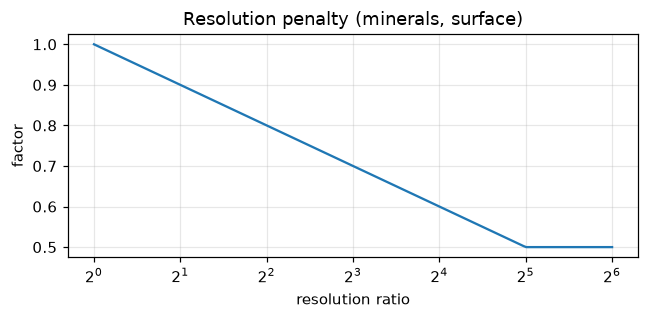

In [18]:
k, mn = config["confidence"]["resolution_k"], config["confidence"]["resolution_min_factor"]
for crit in w:
    ra, rb = A["resolution_m"].get(crit), B["resolution_m"].get(crit)
    print(f"{crit:10s} Samail {ra} m vs Nili {rb} m -> factor {resolution_factor(ra, rb, k, mn):.3f}")
print("coverage:", round(lib["coverage"], 3), " confidence:", round(lib["confidence"], 3))

ratios = np.logspace(0, 6, 200, base=2)
plt.figure(figsize=(6, 3))
plt.plot(ratios, [resolution_factor(r, 1, k, mn) for r in ratios])
plt.xscale("log", base=2); plt.xlabel("resolution ratio"); plt.ylabel("factor"); plt.title("Resolution penalty (minerals, surface)")
plt.tight_layout()

<div dir="rtl" align="right">

## 12. مصفوفة النتائج والتحقق بموقع AMADEE-18

نحسب التشابه لكل زوج (5 مواقع عُمانية × 5 أهداف). المربعات المؤطرة هي الأهداف التي اختير كل موقع من أجلها.

**التحقق:** اختار المنتدى النمساوي للفضاء موقع ظفار لمحاكاة المريخ في 2018. إذا كانت المنهجية جيدة، يجب أن يحصل على ترتيب مرتفع بين المواقع العُمانية في متوسط التشابه مع المريخ.

</div>

Mean Mars similarity ranking: ['samail_ophiolite', 'sharqiya_sands', 'umm_as_samim', 'jebel_shams', 'dhofar_amadee18']
AMADEE-18 reference rank: 5 of 5
Best Mars target per Omani site: {'samail_ophiolite': 'nili_fossae', 'umm_as_samim': 'terra_sirenum_chlorides', 'sharqiya_sands': 'jezero_crater', 'dhofar_amadee18': 'terra_sirenum_chlorides', 'jebel_shams': 'jezero_crater'}


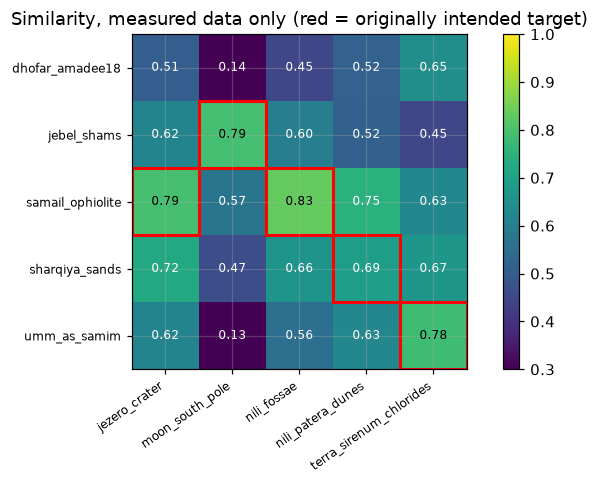

In [19]:
def matrix(scores_list):
    return pd.DataFrame([{"earth": s["earth"], "target": s["target"], "overall": s["overall"]} for s in scores_list]) \
             .pivot(index="earth", columns="target", values="overall").astype(float)

def plot_matrix(m, title, ax, vmin=0.3):
    im = ax.imshow(m.values, cmap="viridis", vmin=vmin, vmax=1.0)
    ax.set_xticks(range(m.shape[1]), m.columns, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(m.shape[0]), m.index, fontsize=8)
    for i, e in enumerate(m.index):
        intended = sites[e].get("intended_targets", [])
        for j, t in enumerate(m.columns):
            v = m.iloc[i, j]
            ax.text(j, i, "-" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if np.isnan(v) or v < 0.75 else "black")
            if t in intended:
                ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec="red", lw=2))
    ax.set_title(title)
    return im

M = matrix(dataset["scores"])
fig, ax = plt.subplots(figsize=(7, 4.5))
plt.colorbar(plot_matrix(M, "Similarity, measured data only (red = originally intended target)", ax), ax=ax)
plt.tight_layout()

v = dataset["validation"]
print("Mean Mars similarity ranking:", v["ranking"])
print(f"AMADEE-18 reference rank: {v['reference_rank']} of {len(v['ranking'])}")
print("Best Mars target per Omani site:", v["best_mars_target"])

<div dir="rtl" align="right">

## 13. تدقيق دقة البيانات

بعد إزالة كل القيم التقديرية، نتحقق من أربعة أمور:

### 13.1 ما هي القيم المتاحة لكل زوج؟
التغطية والثقة لكل زوج (موقع عُماني × هدف). التغطية المنخفضة تعني أن الدرجة مبنية على عدد قليل من الخصائص.

</div>

In [20]:
cov = pd.DataFrame([{"earth": s["earth"], "target": s["target"], "coverage": s["coverage"], "confidence": s["confidence"]}
                    for s in dataset["scores"]])
display(cov.pivot(index="earth", columns="target", values="coverage").round(2))
display(cov.pivot(index="earth", columns="target", values="confidence").round(2))
best = pd.DataFrame({"intended": {e: ", ".join(sites[e].get("intended_targets", [])) or "-" for e in M.index},
                     "best Mars target (measured)": v["best_mars_target"]})
best

target,jezero_crater,moon_south_pole,nili_fossae,nili_patera_dunes,terra_sirenum_chlorides
earth,,,,,
dhofar_amadee18,0.5,0.4,0.5,0.5,0.5
jebel_shams,0.5,0.4,0.5,0.5,0.5
samail_ophiolite,0.5,0.4,0.5,0.5,0.5
sharqiya_sands,0.5,0.4,0.5,0.5,0.5
umm_as_samim,0.5,0.4,0.5,0.5,0.5


target,jezero_crater,moon_south_pole,nili_fossae,nili_patera_dunes,terra_sirenum_chlorides
earth,,,,,
dhofar_amadee18,0.44,0.4,0.44,0.44,0.44
jebel_shams,0.44,0.4,0.44,0.44,0.44
samail_ophiolite,0.44,0.4,0.44,0.44,0.44
sharqiya_sands,0.44,0.4,0.44,0.44,0.44
umm_as_samim,0.44,0.4,0.44,0.44,0.44


,intended,best Mars target (measured)
dhofar_amadee18,-,terra_sirenum_chlorides
jebel_shams,moon_south_pole,jezero_crater
samail_ophiolite,"jezero_crater, nili_fossae",nili_fossae
sharqiya_sands,nili_patera_dunes,jezero_crater
umm_as_samim,terra_sirenum_chlorides,terra_sirenum_chlorides


<div dir="rtl" align="right">

### 13.2 هل مدى التطبيع مناسب؟
المدى القديم الثابت (الخشونة 0–150 م، التضاريس 0–2000 م...) كان أوسع بكثير من القيم المقاسة، فتبدو كل المواقع متشابهة. نقارن انتشار الدرجات (الانحراف المعياري) بين المدى القديم والمدى الجديد المأخوذ من القيم المقاسة مع مقياس لوغاريتمي، **على نفس البيانات المقاسة**.

</div>

score spread (std), old fixed ranges        : 0.137
score spread (std), pooled min-max + log10  : 0.172


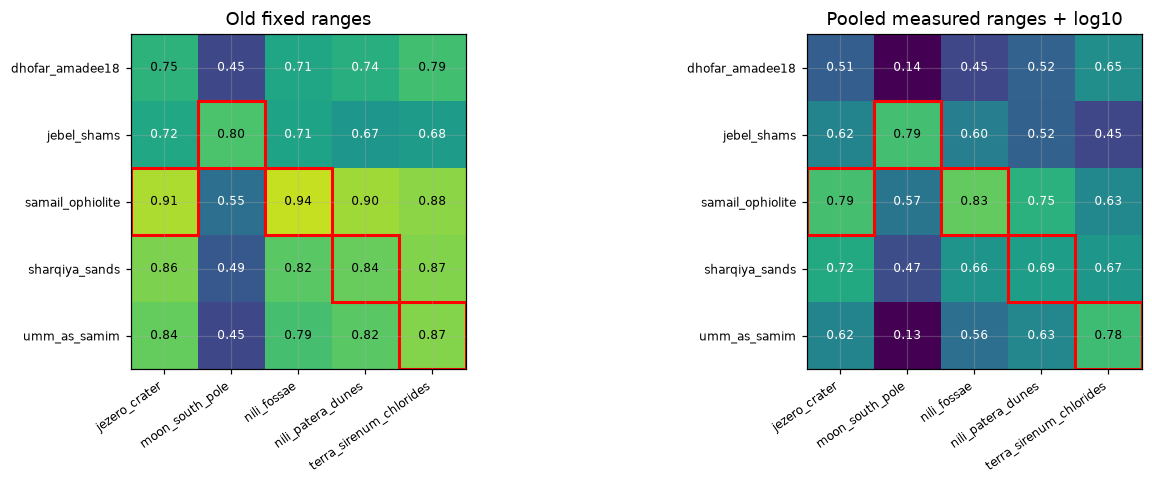

In [21]:
import copy
# The fixed ranges that weights.yaml used before (methodology comparison only).
OLD_RANGES = {"slope_deg": [0, 30], "roughness_m": [0, 150], "relief_m": [0, 2000], "serpentine_index": [0, 1],
              "carbonate_index": [0, 1], "chloride_index": [0, 1], "albedo": [0, 0.5], "thermal_inertia": [0, 2000]}
cfg_old = {**copy.deepcopy(scoring), "feature_ranges": OLD_RANGES, "feature_scale": {}}

def score_all(cfg, weights=None):
    return [{"earth": e["id"], "target": t["id"],
             **similarity(e["raw"], t["raw"], e["resolution_m"], t["resolution_m"], cfg, weights)}
            for e in dataset["earth_sites"] for t in dataset["targets"]]

M_old = matrix(score_all(cfg_old))
spread = lambda M: float(np.nanstd(M.values))
print(f"score spread (std), old fixed ranges        : {spread(M_old):.3f}")
print(f"score spread (std), pooled min-max + log10  : {spread(M):.3f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_matrix(M_old, "Old fixed ranges", axes[0]); plot_matrix(M, "Pooled measured ranges + log10", axes[1])
plt.tight_layout()

<div dir="rtl" align="right">

### 13.3 هل يتغير الترتيب عند تغيير الأوزان؟ (تحليل الحساسية)
نغيّر كل وزن بنسبة ±20% ونرى هل يبقى أفضل هدف مريخي لكل موقع كما هو.

</div>

In [22]:
def best_mars(Mx):
    mars_cols = [c for c in Mx.columns if sites[c]["body"] == "mars"]
    return Mx[mars_cols].idxmax(axis=1)

base = {c: s["weight"] for c, s in config["criteria"].items()}
rows = []
for crit in base:
    for f in (0.8, 1.2):
        wts = dict(base); wts[crit] = base[crit] * f
        rows.append({"change": f"{crit} x{f}", **best_mars(matrix(score_all(scoring, wts))).to_dict()})
sens = pd.DataFrame(rows).set_index("change")
ref_best = best_mars(M).to_dict()
display(sens)
print("Best Mars target unchanged under +/-20% weights:", {e: bool((sens[e] == ref_best[e]).all()) for e in ref_best})

,dhofar_amadee18,jebel_shams,samail_ophiolite,sharqiya_sands,umm_as_samim
change,,,,,
terrain x0.8,terra_sirenum_chlorides,jezero_crater,nili_fossae,jezero_crater,terra_sirenum_chlorides
terrain x1.2,terra_sirenum_chlorides,jezero_crater,nili_fossae,jezero_crater,terra_sirenum_chlorides
mineralogy x0.8,terra_sirenum_chlorides,jezero_crater,nili_fossae,jezero_crater,terra_sirenum_chlorides
mineralogy x1.2,terra_sirenum_chlorides,jezero_crater,nili_fossae,jezero_crater,terra_sirenum_chlorides
surface x0.8,terra_sirenum_chlorides,jezero_crater,nili_fossae,jezero_crater,terra_sirenum_chlorides
surface x1.2,terra_sirenum_chlorides,jezero_crater,nili_fossae,jezero_crater,terra_sirenum_chlorides


Best Mars target unchanged under +/-20% weights: {'dhofar_amadee18': True, 'jebel_shams': True, 'samail_ophiolite': True, 'sharqiya_sands': True, 'umm_as_samim': True}


<div dir="rtl" align="right">

### 13.4 فحوصات تقنية

</div>

In [23]:
checks = []
checks.append(("Terrain grid", f"exactly {common} m (area-weighted average)", "old block method gave 450 m"))
checks.append(("Terrain confidence penalty", f"factor {resolution_factor(common, common, k, mn):.2f}", "terrain shares one grid"))
low = cov[cov.coverage < 0.75]
checks.append(("Pairs with coverage < 0.75", f"{len(low)} of {len(cov)}", "missing values lower confidence"))
wc = {s["id"]: s["provenance"].get("slope_deg", {}).get("window_coverage") for s in all_sites}
checks.append(("DEM window coverage", f"min {min(x for x in wc.values() if x is not None):.0%}", "all terrain windows"))
cr = {s["id"]: s["provenance"]["serpentine_index"]["window_coverage"] for s in dataset["targets"] if "serpentine_index" in s["provenance"]}
checks.append(("CRISM window coverage", ", ".join(f"{k} {x:.0%}" for k, x in cr.items()), "targeted observations cover part of the window"))
checks.append(("Earth albedo product", "MCD43A4 NBAR + Liang (2001)", "MCD43A3 needs Earthdata Login + HDF4"))
pd.DataFrame(checks, columns=["check", "value", "note"]).set_index("check")

,value,note
check,,
Terrain grid,exactly 463 m (area-weighted average),old block method gave 450 m
Terrain confidence penalty,factor 1.00,terrain shares one grid
Pairs with coverage < 0.75,25 of 25,missing values lower confidence
DEM window coverage,min 100%,all terrain windows
CRISM window coverage,"jezero_crater 93%, nili_fossae 26%, terra_sire...",targeted observations cover part of the window
Earth albedo product,MCD43A4 NBAR + Liang (2001),MCD43A3 needs Earthdata Login + HDF4


<div dir="rtl" align="right">

### 13.5 الخلاصة

**ما تغيّر:** لم تعد توجد أي قيمة مكتوبة يدوياً. كل قيمة إما مقاسة من بيانات ناسا مع معرّفات المنتجات، أو غير متاحة مع السبب.

**ما هو مقاس الآن:**
- التضاريس لكل المواقع العشرة (NASADEM, MOLA, LOLA) على شبكة 463 م تماماً.
- الألبيدو للأرض (MODIS) والمريخ (TES).
- القصور الحراري للمريخ من THEMIS.
- مؤشرا السربنتين والكربونات للمريخ من CRISM، مع ملاحظة أن مشاهدات CRISM تغطي جزءاً من النافذة فقط.

**ما هو غير متاح ولماذا:**
- معادن عُمان: تحتاج حساب Earthdata لقراءة EMIT.
- الكلوريد في كل المواقع، والقصور الحراري للأرض: لا توجد معايرة موثّقة.
- لذلك الدرجات الحالية بين عُمان والمريخ مبنية على **التضاريس والألبيدو فقط**، والثقة متوسطة إلى منخفضة (حوالي 0.44).

**النتائج بالبيانات المقاسة فقط** (الجدول في القسم 13.1 والمصفوفة في القسم 12):
- يجب قراءتها مع التحفظ السابق: المعادن لم تدخل المقارنة بعد.
- **تحقق AMADEE-18 لم ينجح حالياً:** موقع ظفار يأتي في **المرتبة الأخيرة** بين المواقع العُمانية. السبب أن نافذته شديدة الاستواء وعالية الألبيدو، بينما أهداف المريخ أكثر تضاريس وأغمق. هذه النتيجة كما حُسبت، ولم نعدّل المنهجية لتحسينها. كما أن إحداثيات الموقع تقريبية.

**الخطوة التالية:** إعداد حساب Earthdata ثم إعادة `python -m analog.compute` لإدخال EMIT، ثم إعادة هذا الدفتر.

</div>